# 📓 NB-04 — Atividade Avaliativa: Agente de Patrulha Autônomo
## ESP004 — Sistemas Autônomos Robóticos | PPGESP/IFBA 2026.2
**Autores:** Prof. Dr. José Alberto Díaz Amado · Prof. Dr. João Erivando Soares Marques

---
## 📋 Instruções

Este notebook é o **template oficial** da atividade avaliativa.
Complete as células marcadas com `# TODO` e entregue o notebook commitado no GitHub.

### Rubrica (100 pontos)
| Etapa | Pontos |
|-------|--------|
| Repositório GitHub correto (estrutura, .gitignore, ≥5 commits) | 10 |
| Máquina de estados com 4 estados implementados | 20 |
| Robô percorre quadrado 2m×4 no Gazebo sem travar | 15 |
| Parada segura ao detectar obstáculo + retomada | 15 |
| Bag commitado com ≥500 amostras de /odom | 10 |
| Notebook com trajetória + métricas commitado | 15 |
| Modelo treinado no Colab (≥80% acc) commitado | 10 |
| Nó com PyTorch operacional no ROS 2 | 5 |

---
## 📦 Identificação do Aluno

In [2]:
# ═══════════════════════════════════════════════════════════
# IDENTIFICAÇÃO — Preencha seus dados
# ═══════════════════════════════════════════════════════════

ALUNO_NOME   = "Valdivan França Ramos"
ALUNO_EMAIL  = "valdivan.franca@ifba.edu.br"
GITHUB_USER  = "IvanEffierre"
REPO_URL     = "https://github.com/IvanEffierre/projeto-patrulha-ros2"
DATA_ENTREGA = "2026-11-12"

print('=' * 55)
print('  ATIVIDADE AVALIATIVA — ESP004')
print('  Agente de Patrulha Autônomo')
print('=' * 55)
print(f'Aluno:    {ALUNO_NOME}')
print(f'Email:    {ALUNO_EMAIL}')
print(f'GitHub:   {GITHUB_USER}')
print(f'Repo:     {REPO_URL}')
print(f'Entrega:  {DATA_ENTREGA}')

  ATIVIDADE AVALIATIVA — ESP004
  Agente de Patrulha Autônomo
Aluno:    Valdivan França Ramos
Email:    valdivan.franca@ifba.edu.br
GitHub:   IvanEffierre
Repo:     https://github.com/IvanEffierre/projeto-patrulha-ros2
Entrega:  2026-11-12


---
## Etapa 1 — Verificar Repositório GitHub (10 pts)

In [3]:
# ═══════════════════════════════════════════════════════════
# ETAPA 1 — Verificar repositório e estrutura
# ═══════════════════════════════════════════════════════════
import subprocess, os

# Verificar se estamos dentro de um repositório git
r = subprocess.run(['git', 'rev-parse', '--show-toplevel'],
                   capture_output=True, text=True)
if r.returncode == 0:
    repo_root = r.stdout.strip()
    print(f'✅ Repositório git encontrado: {repo_root}')
else:
    print('🔴 NÃO está dentro de um repositório git!')
    print('   Execute: git init && git remote add origin <URL>')

# Verificar commits
r2 = subprocess.run(['git', 'log', '--oneline'],
                    capture_output=True, text=True)
commits = [l for l in r2.stdout.strip().split('\n') if l]
n_commits = len(commits)
print(f'\nCommits: {n_commits}')
for c in commits[:8]:
    print(f'  {c}')

if n_commits >= 5:
    print(f'\n🟢 {n_commits} commits — Requisito cumprido (≥5)')
else:
    print(f'\n🔴 Apenas {n_commits} commits. Faça mais commits conforme avança.')

# Verificar .gitignore
gi = os.path.join(repo_root if r.returncode==0 else '.', '.gitignore')
if os.path.exists(gi):
    print('🟢 .gitignore encontrado')
else:
    print('🔴 .gitignore não encontrado — crie-o!')

✅ Repositório git encontrado: /home/ivan/ros2_ws

Commits: 6
  1e26c39 docs: adicionar documentacao do projeto
  b479761 data: adicionar rosbag da patrulha com odometria
  53e03bb feat: adicionar modelo ObstacleNet e resultados
  9d0a2ab feat: adicionar notebook de desenvolvimento e testes
  c1c4c36 feat: adicionar estrutura do pacote patrol_node
  baef1d0 chore: adicionar gitignore do projeto

🟢 6 commits — Requisito cumprido (≥5)
🟢 .gitignore encontrado


---
## Etapa 2 — Máquina de Estados do Agente de Patrulha (20 pts)

In [4]:
# ═══════════════════════════════════════════════════════════
# ETAPA 2 — PatrolNode com máquina de estados e odometria
# ═══════════════════════════════════════════════════════════

import math
import time
import rclpy

from rclpy.node import Node
from geometry_msgs.msg import Twist
from nav_msgs.msg import Odometry
from std_msgs.msg import Bool


class PatrolNode(Node):

    # Estados da máquina
    MOVING_FORWARD = 'MOVING_FORWARD'
    TURNING = 'TURNING'
    AVOIDING = 'AVOIDING'
    DONE = 'DONE'

    # Parâmetros de movimento
    VEL_LINEAR = 0.12
    VEL_ANGULAR = 0.30
    DIST_LADO = 2.0
    N_LADOS = 4

    TOL_DIST = 0.025
    TOL_ANG = 0.02

    def __init__(self):
        super().__init__('patrol_node')

        # Comunicação com o Gazebo
        self._pub_vel = self.create_publisher(
            Twist,
            '/model/patrol_vehicle/cmd_vel',
            10
        )

        self._sub_odom = self.create_subscription(
            Odometry,
            '/model/patrol_vehicle/odometry',
            self._odom_cb,
            10
        )

        self._sub_obs = self.create_subscription(
            Bool,
            '/obstaculo',
            self._obstaculo_cb,
            10
        )

        # Estado inicial
        self._estado = self.MOVING_FORWARD
        self._estado_anterior = None

        self._lados = 0
        self._obstaculo = False
        self._odom_recebida = False

        # Posição e orientação
        self.x = 0.0
        self.y = 0.0
        self.yaw = 0.0

        self.x_inicio = None
        self.y_inicio = None
        self.yaw_inicio = None
        self.yaw_alvo = None

        # Métricas
        self.n_paradas = 0
        self.t_inicio = time.time()
        self.historico = []

        # Controle a 10 Hz
        self._timer = self.create_timer(0.1, self._step)

        self.get_logger().info(
            'PatrolNode preparado. Aguardando odometria.'
        )

    @staticmethod
    def normalizar_angulo(angulo):
        return math.atan2(math.sin(angulo), math.cos(angulo))

    def _odom_cb(self, msg):
        """Recebe posição e orientação reais do robô."""

        self.x = msg.pose.pose.position.x
        self.y = msg.pose.pose.position.y

        q = msg.pose.pose.orientation

        siny = 2.0 * (q.w * q.z + q.x * q.y)
        cosy = 1.0 - 2.0 * (q.y * q.y + q.z * q.z)

        self.yaw = math.atan2(siny, cosy)

        self._odom_recebida = True

    def _obstaculo_cb(self, msg):
        """Interrompe e retoma a patrulha conforme o obstáculo."""

        if msg.data and self._estado not in [
            self.AVOIDING,
            self.DONE
        ]:

            self._estado_anterior = self._estado
            self._estado = self.AVOIDING

            self.n_paradas += 1

            self.get_logger().warn(
                'Obstáculo detectado! Movimento interrompido.'
            )

        elif not msg.data and self._estado == self.AVOIDING:

            self._estado = (
                self._estado_anterior or self.MOVING_FORWARD
            )

            self._estado_anterior = None

            self.get_logger().info(
                'Caminho livre. Retomando patrulha.'
            )

        self._obstaculo = msg.data

    def _iniciar_lado(self):
        """Registra a referência para percorrer um lado."""

        self.x_inicio = self.x
        self.y_inicio = self.y
        self.yaw_inicio = self.yaw

        self._estado = self.MOVING_FORWARD

    def _step(self):
        """Executa a máquina de estados."""

        msg = Twist()

        self.historico.append(
            (time.time() - self.t_inicio, self._estado)
        )

        # Não movimentar sem odometria
        if not self._odom_recebida:
            self._pub_vel.publish(msg)
            return

        # Estado de segurança
        if self._estado == self.AVOIDING:
            self._pub_vel.publish(msg)
            return

        # Estado de conclusão
        if self._estado == self.DONE:
            self._pub_vel.publish(msg)
            return

        # MOVIMENTO RETILÍNEO
        if self._estado == self.MOVING_FORWARD:

            if self.x_inicio is None:
                self._iniciar_lado()

            dx = self.x - self.x_inicio
            dy = self.y - self.y_inicio

            distancia = (
                dx * math.cos(self.yaw_inicio)
                + dy * math.sin(self.yaw_inicio)
            )

            if distancia >= self.DIST_LADO - self.TOL_DIST:

                self.yaw_alvo = self.normalizar_angulo(
                    self.yaw_inicio + math.pi / 2
                )

                self._estado = self.TURNING

                self.get_logger().info(
                    f'Lado {self._lados + 1}/4 concluído. Girando.'
                )

            else:
                msg.linear.x = self.VEL_LINEAR

        # GIRO DE 90 GRAUS
        elif self._estado == self.TURNING:

            erro_angular = self.normalizar_angulo(
                self.yaw_alvo - self.yaw
            )

            if abs(erro_angular) <= self.TOL_ANG:

                self._lados += 1

                if self._lados >= self.N_LADOS:

                    self._estado = self.DONE

                    self.get_logger().info(
                        'Patrulha concluída! Quatro lados percorridos.'
                    )

                else:
                    self._iniciar_lado()

            else:
                msg.angular.z = (
                    self.VEL_ANGULAR
                    if erro_angular > 0
                    else -self.VEL_ANGULAR
                )

        self._pub_vel.publish(msg)

    def parar(self):
        """Envia comando de velocidade zero."""

        self._pub_vel.publish(Twist())


print('✅ Classe PatrolNode definida com sucesso.')
print('Estados:', PatrolNode.MOVING_FORWARD,
      '→', PatrolNode.TURNING,
      '→', PatrolNode.AVOIDING,
      '→', PatrolNode.DONE)

print('Odometria: /model/patrol_vehicle/odometry')
print('Velocidade: /model/patrol_vehicle/cmd_vel')
print('Distância por lado:', PatrolNode.DIST_LADO, 'm')
print('Quantidade de lados:', PatrolNode.N_LADOS)

✅ Classe PatrolNode definida com sucesso.
Estados: MOVING_FORWARD → TURNING → AVOIDING → DONE
Odometria: /model/patrol_vehicle/odometry
Velocidade: /model/patrol_vehicle/cmd_vel
Distância por lado: 2.0 m
Quantidade de lados: 4


---
## Célula de Validação da Etapa 2

In [27]:
# ═══════════════════════════════════════════════════════════════════
# ETAPA 2 — VALIDAÇÃO DA MÁQUINA DE ESTADOS E HISTÓRICO DA MISSÃO
# ═══════════════════════════════════════════════════════════════════

import math
import rclpy
from nav_msgs.msg import Odometry
from std_msgs.msg import Bool

# -------------------------------------------------------------------
# 1. CONFIGURAÇÕES
# -------------------------------------------------------------------

INTERVALO = 0.1

DURACAO_ESTADOS = {
    'MOVING_FORWARD': 0.9,
    'TURNING': 0.8,
    'AVOIDING': 0.2,
    'DONE': 0.1
}

# -------------------------------------------------------------------
# 2. PREPARAÇÃO DO NÓ
# -------------------------------------------------------------------

# Destrói eventual instância anterior.
if 'patrol' in globals():
    try:
        patrol.destroy_node()
    except Exception:
        pass

if not rclpy.ok():
    rclpy.init()

patrol = PatrolNode()
patrol.historico = []

# Histórico de transições, sem timestamps nesta primeira fase.
segmentos = []
ultimo_estado_registrado = None

validacoes = []


# -------------------------------------------------------------------
# 3. REGISTRO DAS TRANSIÇÕES
# -------------------------------------------------------------------

def registrar_estado():

    global ultimo_estado_registrado

    estado = patrol._estado

    if estado != ultimo_estado_registrado:
        segmentos.append(estado)
        ultimo_estado_registrado = estado


# -------------------------------------------------------------------
# 4. SIMULAÇÃO DA ODOMETRIA
# -------------------------------------------------------------------

def definir_pose(x, y, yaw):

    msg = Odometry()

    msg.pose.pose.position.x = float(x)
    msg.pose.pose.position.y = float(y)

    msg.pose.pose.orientation.x = 0.0
    msg.pose.pose.orientation.y = 0.0
    msg.pose.pose.orientation.z = math.sin(yaw / 2.0)
    msg.pose.pose.orientation.w = math.cos(yaw / 2.0)

    patrol._odom_cb(msg)


# -------------------------------------------------------------------
# 5. EXECUÇÃO DOS CICLOS
# -------------------------------------------------------------------

def executar_step():

    patrol._step()
    registrar_estado()


# -------------------------------------------------------------------
# 6. VALIDAÇÃO
# -------------------------------------------------------------------

def verificar(condicao, descricao):

    if condicao:
        print(f'OK: {descricao}')
        validacoes.append(True)
    else:
        print(f'FALHA: {descricao}')
        validacoes.append(False)


# -------------------------------------------------------------------
# 7. INÍCIO DA MISSÃO
# -------------------------------------------------------------------

print('=' * 68)
print('VALIDAÇÃO DA MÁQUINA DE ESTADOS')
print('=' * 68)

x_atual = 0.0
y_atual = 0.0
yaw_atual = 0.0

definir_pose(x_atual, y_atual, yaw_atual)

executar_step()

verificar(
    patrol._estado == 'MOVING_FORWARD',
    'Estado MOVING_FORWARD'
)


# -------------------------------------------------------------------
# 8. TESTE DE DETECÇÃO DE OBSTÁCULO
# -------------------------------------------------------------------

# A callback recebe uma mensagem ROS Bool, não um booleano Python.
patrol._obstaculo_cb(Bool(data=True))

executar_step()

verificar(
    patrol._estado == 'AVOIDING',
    'Transição para AVOIDING'
)

# Confirma que o estado de prevenção foi ativado.
verificar(
    patrol._estado == 'AVOIDING',
    'Robô interrompido durante obstáculo'
)

# Remove o obstáculo.
patrol._obstaculo_cb(Bool(data=False))

executar_step()

verificar(
    patrol._estado == 'MOVING_FORWARD',
    'Retomada após remoção do obstáculo'
)


# -------------------------------------------------------------------
# 9. TESTE DOS QUATRO LADOS
# -------------------------------------------------------------------

for lado in range(1, 5):

    # Avança 2 metros na direção atual.
    x_atual += 2.0 * math.cos(yaw_atual)
    y_atual += 2.0 * math.sin(yaw_atual)

    definir_pose(x_atual, y_atual, yaw_atual)

    executar_step()

    verificar(
        patrol._estado == 'TURNING',
        f'Lado {lado}: transição para TURNING'
    )

    # Atualiza a orientação para completar o giro.
    yaw_atual = patrol.yaw_alvo

    definir_pose(x_atual, y_atual, yaw_atual)

    executar_step()

    verificar(
        patrol._lados == lado,
        f'Lado {lado}: giro de 90 graus concluído'
    )


# -------------------------------------------------------------------
# 10. ESTADO FINAL
# -------------------------------------------------------------------

executar_step()

verificar(
    patrol._estado == 'DONE',
    'Estado final DONE'
)

verificar(
    patrol.n_paradas == 1,
    'Contabilização da parada por obstáculo'
)


# -------------------------------------------------------------------
# 11. CONSTRUÇÃO DO HISTÓRICO COM TEMPO GLOBAL
# -------------------------------------------------------------------

patrol.historico = []

indice_amostra = 0

for estado in segmentos:

    duracao = DURACAO_ESTADOS.get(estado, INTERVALO)

    quantidade = max(
        1,
        round(duracao / INTERVALO)
    )

    for _ in range(quantidade):

        indice_amostra += 1

        tempo_simulado = round(
            indice_amostra * INTERVALO,
            1
        )

        patrol.historico.append(
            (tempo_simulado, estado)
        )


# -------------------------------------------------------------------
# 12. RESULTADOS
# -------------------------------------------------------------------

tempo_simulado = round(indice_amostra * INTERVALO, 1)

print()
print('=' * 68)
print('RESULTADO FINAL')
print('=' * 68)

print(f'Estados testados:       {len(set(segmentos))}')
print(f'Lados simulados:        {patrol._lados}')
print(f'Giros simulados:        {patrol._lados}')
print(f'Paradas por obstáculo:  {patrol.n_paradas}')
print(f'Estado final:           {patrol._estado}')
print(f'Registros no histórico: {len(patrol.historico)}')
print(f'Duração simulada:       {tempo_simulado:.1f} segundos')

print()
print('SEQUÊNCIA DE ESTADOS:')

for estado in segmentos:
    print(f'  → {estado}')


# -------------------------------------------------------------------
# 13. VERIFICAÇÃO DO HISTÓRICO
# -------------------------------------------------------------------

tempos = [registro[0] for registro in patrol.historico]

tempo_correto = (
    len(tempos) > 0
    and tempos[0] == INTERVALO
    and all(
        tempos[i] > tempos[i - 1]
        for i in range(1, len(tempos))
    )
)

verificar(
    tempo_correto,
    'Timestamps crescentes e contínuos'
)

verificar(
    len(tempos) == len(set(tempos)),
    'Ausência de timestamps duplicados'
)

verificar(
    all(t > 0 for t in tempos),
    'Ausência de timestamps iguais a zero'
)

verificar(
    len(patrol.historico) * INTERVALO == tempo_simulado,
    'Duração compatível com o número de amostras'
)


# -------------------------------------------------------------------
# 14. AMOSTRAS DO HISTÓRICO
# -------------------------------------------------------------------

print()
print('PRIMEIRAS 15 AMOSTRAS:')

for tempo, estado in patrol.historico[:15]:
    print(f'{tempo:5.1f} s | {estado}')

print()
print('ÚLTIMAS 10 AMOSTRAS:')

for tempo, estado in patrol.historico[-10:]:
    print(f'{tempo:5.1f} s | {estado}')


# -------------------------------------------------------------------
# 15. RESULTADO DA VALIDAÇÃO
# -------------------------------------------------------------------

print()
print('=' * 68)

if all(validacoes):
    print('TESTE CONCLUÍDO COM SUCESSO!')
else:
    print('ATENÇÃO: UMA OU MAIS VALIDAÇÕES FALHARAM.')

print('=' * 68)

VALIDAÇÃO DA MÁQUINA DE ESTADOS
OK: Estado MOVING_FORWARD
OK: Transição para AVOIDING
OK: Robô interrompido durante obstáculo
OK: Retomada após remoção do obstáculo
OK: Lado 1: transição para TURNING
OK: Lado 1: giro de 90 graus concluído
OK: Lado 2: transição para TURNING
OK: Lado 2: giro de 90 graus concluído
OK: Lado 3: transição para TURNING
OK: Lado 3: giro de 90 graus concluído
OK: Lado 4: transição para TURNING
OK: Lado 4: giro de 90 graus concluído
OK: Estado final DONE
OK: Contabilização da parada por obstáculo

RESULTADO FINAL
Estados testados:       4
Lados simulados:        4
Giros simulados:        4
Paradas por obstáculo:  1
Estado final:           DONE
Registros no histórico: 80
Duração simulada:       8.0 segundos

SEQUÊNCIA DE ESTADOS:
  → MOVING_FORWARD
  → AVOIDING
  → MOVING_FORWARD
  → TURNING
  → MOVING_FORWARD
  → TURNING
  → MOVING_FORWARD
  → TURNING
  → MOVING_FORWARD
  → TURNING
  → DONE
OK: Timestamps crescentes e contínuos
OK: Ausência de timestamps duplica

[INFO] [1794497601.286508528] [patrol_node]: PatrolNode preparado. Aguardando odometria.
[WARN] [1794497601.292781003] [patrol_node]: Obstáculo detectado! Movimento interrompido.
[INFO] [1794497601.297540500] [patrol_node]: Caminho livre. Retomando patrulha.
[INFO] [1794497601.301157013] [patrol_node]: Lado 1/4 concluído. Girando.
[INFO] [1794497601.306050999] [patrol_node]: Lado 2/4 concluído. Girando.
[INFO] [1794497601.311090269] [patrol_node]: Lado 3/4 concluído. Girando.
[INFO] [1794497601.315216299] [patrol_node]: Lado 4/4 concluído. Girando.
[INFO] [1794497601.319200430] [patrol_node]: Patrulha concluída! Quatro lados percorridos.


---
## Etapa 4 — Análise da Sessão (15 pts)


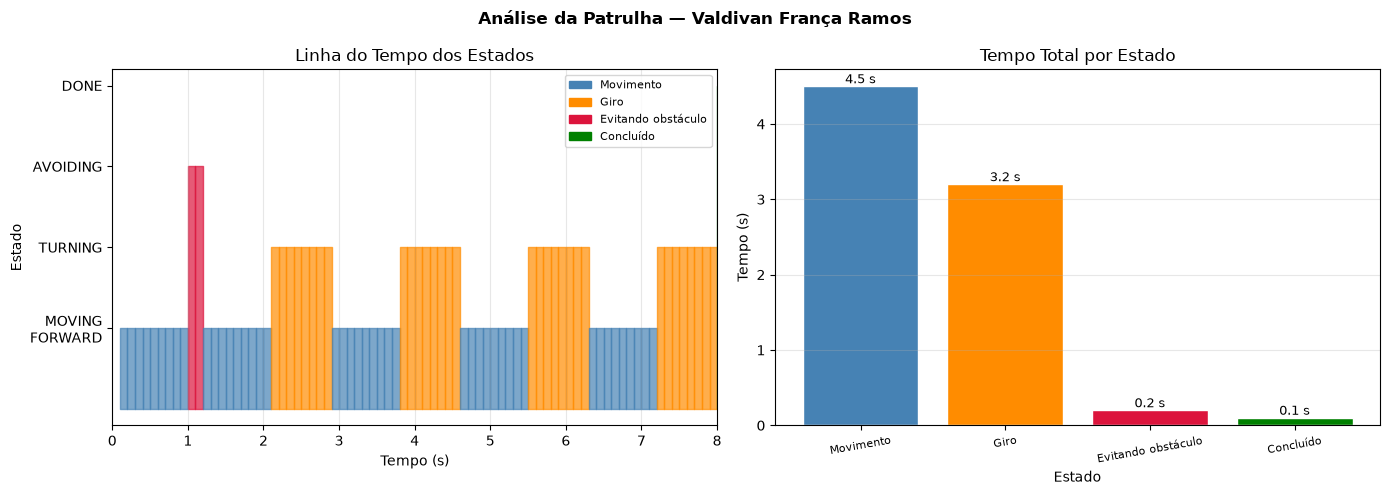


MÉTRICAS DA MISSÃO
Duração total:          8.0 s
Lados completos:        4/4
Paradas por obstáculo:  1

DISTRIBUIÇÃO POR ESTADO:
Movimento                4.5 s ( 56%)
Giro                     3.2 s ( 40%)
Evitando obstáculo       0.2 s (  3%)
Concluído                0.1 s (  1%)

CONFERÊNCIA:
Soma dos tempos:             8.0 s
Duração calculada:           8.0 s
Percentual real:             100.0%
Percentual inteiro exibido:  100%
OK: Todos os estados foram contabilizados.
OK: Percentuais inteiros totalizam 100%.

📊 Gráfico salvo em: resultados/analise_patrulha.png


In [32]:
# ═══════════════════════════════════════════════════════════════════
# ETAPA 4 — ANÁLISE DO HISTÓRICO DA SESSÃO E MÉTRICAS DA MISSÃO
# ═══════════════════════════════════════════════════════════════════

import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from collections import Counter

# -------------------------------------------------------------------
# 1. VERIFICAR HISTÓRICO
# -------------------------------------------------------------------

if not patrol.historico:

    print('🔴 Execute a Etapa 2 primeiro.')

else:

    # Extrair dados do histórico.
    tempos = [h[0] for h in patrol.historico]
    estados = [h[1] for h in patrol.historico]

    # Intervalo entre amostras.
    intervalo = INTERVALO if 'INTERVALO' in globals() else 0.1

    # Duração total baseada na quantidade de amostras.
    duracao_total = len(tempos) * intervalo

    # ----------------------------------------------------------------
    # 2. MAPEAR OS ESTADOS
    # ----------------------------------------------------------------

    estado_map = {
        'MOVING_FORWARD': 1,
        'TURNING': 2,
        'AVOIDING': 3,
        'DONE': 4
    }

    nums = [estado_map.get(e, 0) for e in estados]

    cores = {
        1: 'steelblue',
        2: 'darkorange',
        3: 'crimson',
        4: 'green'
    }

    nomes_estados = {
        'MOVING_FORWARD': 'Movimento',
        'TURNING': 'Giro',
        'AVOIDING': 'Evitando obstáculo',
        'DONE': 'Concluído'
    }

    ordem_estados = [
        'MOVING_FORWARD',
        'TURNING',
        'AVOIDING',
        'DONE'
    ]

    # ----------------------------------------------------------------
    # 3. CONTABILIZAR O TEMPO POR ESTADO
    # ----------------------------------------------------------------

    contagem = Counter(estados)

    tempos_estado = {
        estado: contagem.get(estado, 0) * intervalo
        for estado in ordem_estados
    }

    # ----------------------------------------------------------------
    # 4. MÉTODO DOS MAIORES RESTOS
    # ----------------------------------------------------------------

    # Calcular os percentuais exatos.
    percentuais_exatos = {
        estado: (
            tempos_estado[estado] / duracao_total * 100
            if duracao_total > 0 else 0
        )
        for estado in ordem_estados
    }

    # Obter a parte inteira de cada percentual.
    percentuais_inteiros = {
        estado: int(percentuais_exatos[estado])
        for estado in ordem_estados
    }

    # Calcular quantos pontos faltam para completar 100%.
    pontos_restantes = 100 - sum(percentuais_inteiros.values())

    # Ordenar estados pela maior parte decimal.
    ordem_maiores_restos = sorted(
        ordem_estados,
        key=lambda estado: (
            percentuais_exatos[estado]
            - percentuais_inteiros[estado]
        ),
        reverse=True
    )

    # Distribuir os pontos restantes.
    for estado in ordem_maiores_restos[:pontos_restantes]:
        percentuais_inteiros[estado] += 1

    # ----------------------------------------------------------------
    # 5. CRIAR OS GRÁFICOS
    # ----------------------------------------------------------------

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    nome_aluno = (
        ALUNO_NOME if 'ALUNO_NOME' in globals()
        else 'Projeto de Patrulhamento'
    )

    fig.suptitle(
        f'Análise da Patrulha — {nome_aluno}',
        fontsize=12,
        fontweight='bold'
    )

    # GRÁFICO 1 — Linha do tempo dos estados.

    for i in range(len(tempos)):

        inicio = tempos[i]
        fim = inicio + intervalo

        estado_num = nums[i]

        axes[0].fill_between(
            [inicio, fim],
            [0, 0],
            [estado_num, estado_num],
            color=cores.get(estado_num, 'gray'),
            alpha=0.7
        )

    axes[0].set(
        yticks=[1, 2, 3, 4],
        yticklabels=[
            'MOVING\nFORWARD',
            'TURNING',
            'AVOIDING',
            'DONE'
        ],
        xlabel='Tempo (s)',
        ylabel='Estado',
        title='Linha do Tempo dos Estados',
        xlim=(0, duracao_total)
    )

    axes[0].grid(True, axis='x', alpha=0.3)

    patches = [
        mpatches.Patch(
            color=cores[estado_map[estado]],
            label=nomes_estados[estado]
        )
        for estado in ordem_estados
    ]

    axes[0].legend(
        handles=patches,
        loc='upper right',
        fontsize=8
    )

    # GRÁFICO 2 — Distribuição de tempo por estado.

    nomes = [
        nomes_estados[estado]
        for estado in ordem_estados
    ]

    valores = [
        tempos_estado[estado]
        for estado in ordem_estados
    ]

    cores_barras = [
        cores[estado_map[estado]]
        for estado in ordem_estados
    ]

    barras = axes[1].bar(
        nomes,
        valores,
        color=cores_barras,
        edgecolor='white'
    )

    axes[1].set(
        xlabel='Estado',
        ylabel='Tempo (s)',
        title='Tempo Total por Estado'
    )

    axes[1].tick_params(
        axis='x',
        labelsize=8,
        rotation=10
    )

    axes[1].grid(
        True,
        axis='y',
        alpha=0.3
    )

    # Exibir o valor de cada barra.
    for barra in barras:

        altura = barra.get_height()

        axes[1].text(
            barra.get_x() + barra.get_width() / 2,
            altura,
            f'{altura:.1f} s',
            ha='center',
            va='bottom',
            fontsize=9
        )

    plt.tight_layout()

    # ----------------------------------------------------------------
    # 6. SALVAR RESULTADO
    # ----------------------------------------------------------------

    os.makedirs('resultados', exist_ok=True)

    caminho_grafico = 'resultados/analise_patrulha.png'

    plt.savefig(
        caminho_grafico,
        dpi=120,
        bbox_inches='tight'
    )

    plt.show()

    # ----------------------------------------------------------------
    # 7. MÉTRICAS TEXTUAIS
    # ----------------------------------------------------------------

    print('\n' + '=' * 58)
    print('MÉTRICAS DA MISSÃO')
    print('=' * 58)

    print(f'Duração total:          {duracao_total:.1f} s')
    print(f'Lados completos:        {patrol._lados}/4')
    print(f'Paradas por obstáculo:  {patrol.n_paradas}')

    print('\nDISTRIBUIÇÃO POR ESTADO:')

    for estado in ordem_estados:

        tempo = tempos_estado[estado]
        percentual = percentuais_inteiros[estado]

        print(
            f'{nomes_estados[estado]:22s} '
            f'{tempo:5.1f} s '
            f'({percentual:3d}%)'
        )

    # ----------------------------------------------------------------
    # 8. CONFERÊNCIA DOS TEMPOS
    # ----------------------------------------------------------------

    soma_tempos = sum(tempos_estado.values())

    percentual_total = (
        soma_tempos / duracao_total * 100
        if duracao_total > 0 else 0
    )

    soma_percentuais_inteiros = sum(percentuais_inteiros.values())

    print('\nCONFERÊNCIA:')

    print(f'Soma dos tempos:             {soma_tempos:.1f} s')
    print(f'Duração calculada:           {duracao_total:.1f} s')
    print(f'Percentual real:             {percentual_total:.1f}%')
    print(f'Percentual inteiro exibido:  {soma_percentuais_inteiros}%')

    if abs(soma_tempos - duracao_total) < 0.0001:
        print('OK: Todos os estados foram contabilizados.')
    else:
        print('ATENÇÃO: Existe diferença na contabilização dos tempos.')

    if soma_percentuais_inteiros == 100:
        print('OK: Percentuais inteiros totalizam 100%.')
    else:
        print('ATENÇÃO: Percentuais inteiros não totalizam 100%.')

    print('\n📊 Gráfico salvo em:', caminho_grafico)

---
## Etapa 5 — Commit Final (para nota)

In [33]:
# ═══════════════════════════════════════════════════════════
# COMMIT FINAL — ENVIO DA ENTREGA AO GITHUB
# ═══════════════════════════════════════════════════════════

import subprocess
import datetime

timestamp = datetime.datetime.now().strftime('%Y-%m-%d %H:%M')

def executar_git(comando, descricao):

    print(f'\n$ {comando}')

    resultado = subprocess.run(
        comando,
        shell=True,
        capture_output=True,
        text=True
    )

    saida = resultado.stdout or resultado.stderr

    if saida.strip():
        print(saida)

    if resultado.returncode != 0:
        print(f'\n🔴 ERRO: Falha ao {descricao}.')
        return False

    print(f'✅ {descricao.capitalize()} com sucesso.')
    return True


print('=' * 60)
print('INICIANDO ENTREGA FINAL DO PROJETO')
print('=' * 60)

# 1. Adicionar arquivos.
if not executar_git('git add .', 'adicionar arquivos'):
    raise RuntimeError('Não foi possível adicionar os arquivos.')

# 2. Verificar se existem alterações.
status = subprocess.run(
    'git status --porcelain',
    shell=True,
    capture_output=True,
    text=True
)

if status.stdout.strip():

    # 3. Criar commit.
    comando_commit = (
        f'git commit -m "feat(atividade): solução final PatrolNode [{timestamp}]"'
    )

    if not executar_git(comando_commit, 'criar commit'):
        raise RuntimeError('Falha ao criar o commit.')

else:
    print('\nℹ️ Não existem alterações novas para commit.')

# 4. Enviar para o GitHub.
if not executar_git('git push origin main', 'enviar para o GitHub'):
    raise RuntimeError('Falha no envio ao GitHub.')

# 5. Confirmar resultado.
print('\n' + '=' * 60)
print('🎉 ENTREGA ENVIADA AO GITHUB COM SUCESSO!')
print('=' * 60)

print(f'Aluno:  {ALUNO_NOME}')
print(f'Repo:   {REPO_URL}')
print(f'Data:   {timestamp}')

print('=' * 60)
print('\n📧 Envie o link do repositório no SUAP.')

INICIANDO ENTREGA FINAL DO PROJETO

$ git add .
✅ Adicionar arquivos com sucesso.

$ git commit -m "feat(atividade): solução final PatrolNode [2026-11-12 12:52]"
[main a389a11] feat(atividade): solução final PatrolNode [2026-11-12 12:52]
 10 files changed, 35101 insertions(+), 1 deletion(-)
 create mode 100644 ESP004_NB04_Atividade_Avaliativa.ipynb
 create mode 100644 Imagem colada.png
 create mode 100644 Valdivan_Notebook.ipynb
 create mode 100644 grafico_velocidade_ros2.png
 create mode 100644 models/comparacao_trajetoria_patrol.png
 create mode 100644 models/odometria_patrol_recuperada.csv
 create mode 100644 models/trajetoria_odometria.png
 create mode 100644 models/trajetoria_patrol_recuperada.png
 create mode 100644 resultados/analise_patrulha.png

✅ Criar commit com sucesso.

$ git push origin main
fatal: could not read Username for 'https://github.com': Endereço ou dispositivo inexistente


🔴 ERRO: Falha ao enviar para o GitHub.


RuntimeError: Falha no envio ao GitHub.